In [1]:
import torch

flushing = torch.set_flush_denormal(True)
print(f"Floating point flushing is set to {flushing}")

torch.manual_seed(0)
torch.set_num_threads(1)

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
print(f"Using device: {device}")

Floating point flushing is set to True
Using device: cpu


In [105]:
import torch
import torch.nn as nn
from typing import Any

from thesis_code.network_components.neurons import MaskedRLeaky, MaskedRSynaptic
from thesis_code.network_components.linears import DaleslawLinear, MaskedKaimingLinear

class RecurrentLayer(nn.Module):
    def __init__(self,
        forward_matrix: torch.Tensor,
        recurrent_matrix: torch.Tensor,
        refractory_period: int = 0,
    ) -> None:
        super().__init__()
        self.n_neurons = recurrent_matrix.shape[0]

        assert forward_matrix.shape[1] == self.n_neurons, \
            f"forward_matrix outputs {forward_matrix.shape[1]} neurons, recurrent_matrix has {self.n_neurons}"

        self.weights = DaleslawLinear(forward_matrix)
        print(self.weights.get_weights())
        print("Input weights are all positive")

        assert isinstance(refractory_period, int) and refractory_period >= 0, \
            "refractory_period is set incorrectly"

        self.refractory_period = refractory_period
        self.refractory_buffer: torch.Tensor | None = None

    def reset(self) -> None:
        self._reset_neuron_state()
        self.weights.reset()
        self.refractory_buffer = None

    def _reset_neuron_state(self) -> None:
        raise NotImplementedError

    def get_weights(self) -> tuple[torch.Tensor, torch.Tensor]:
        return self.weights.get_weights(), self.neurons.get_recurrent_weights()

    def _compute_refractory_period(self, spk: torch.Tensor, mem: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        """
        Sets a mask to mute all spiking activity for a neuron activity for n timesteps after this neuron has spiked has occurred.
        Also keeps membrane potential at 0 (in snntorch language. This corresponds with -70mV in real-life).
        It leaves the synapses of SynapticRecurrentLayer alone.

        Inspired by:
        Li, Yang, Xinyi Zeng, Zhe Xue, Pinxian Zeng, Zikai Zhang, and Yan Wang. 2025. 
        “Incorporating the Refractory Period into Spiking Neural Networks through Spike-Triggered Threshold Dynamics.” 
        In arXiv [Cs.CV]. September 22. arXiv. https://doi.org/10.48550/arXiv.2509.17769.
        """
        if self.refractory_period <= 0:
            return spk, mem

        if self.refractory_buffer is None or self.refractory_buffer.shape != spk.shape:
            self.refractory_buffer = torch.zeros_like(spk, dtype=torch.int16)

        # print(f"Refractory buffer is: {self.refractory_buffer}")

        refractory = self.refractory_buffer > 0
        # print(f"Refractory is: {refractory}")

        # print(f"Spikes before mask: {spk}")
        spk = spk.masked_fill(refractory, 0.0)                      # disable spiking for neurons in refractory periods
        # print(f"Spikes after mask: {spk}")

        # print(f"Mems before clamp: {mem}")
        # mem = torch.where(refractory, torch.zeros_like(mem), mem)   # clamp mems to 0 for neurons in refractory periods
        # print(f"Mems after clamp: {mem}")

        self.refractory_buffer = torch.where(
            spk > 0,
            torch.full_like(self.refractory_buffer, self.refractory_period),    # set the buffer to the integer number of timesteps the buffer should apply if spiking
            (self.refractory_buffer - 1).clamp_min(0),                          # decrease the buffer by 1 for each timestep and clamp to 0
        )
        return spk, mem

    def _step(self, x: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self._step(self.weights(x))

    def forward_sequence(self, x_seq: torch.Tensor) -> torch.Tensor:
        x_seq = self.weights(x_seq)
        return torch.stack([self._step(x) for x in x_seq.unbind(0)], dim=0)

class StandardRecurrentLayer(RecurrentLayer):
    def __init__(self,
        forward_matrix: torch.Tensor,
        recurrent_matrix: torch.Tensor,
        beta: torch.Tensor | float,
        spike_grad: Any,
        fully_learnable: bool = True,
        refractory_period: int = 0,
    ) -> None:
        super().__init__(forward_matrix, recurrent_matrix, refractory_period)
        self.neurons = MaskedRLeaky(
            beta=beta,
            linear_features=self.n_neurons,
            init_hidden=False,
            spike_grad=spike_grad,
            learn_beta=fully_learnable,
            rec_matrix=recurrent_matrix,
            threshold=torch.ones(self.n_neurons),
        )
        self.spk, self.mem = self.neurons.init_rleaky()

    def _reset_neuron_state(self) -> None:
        self.spk, self.mem = self.neurons.init_rleaky()
        self.neurons.reset_recurrent_weights()

    def _step(self, x: torch.Tensor) -> torch.Tensor:
        # self.spk, self.mem = self.neurons(x, self.spk, self.mem)
        spk, mem = self.neurons(x, self.spk, self.mem)
        self.spk, self.mem = self._compute_refractory_period(spk, mem)
        # print(self.spk.clone().detach().squeeze().numpy())
        return self.spk

In [96]:
import snntorch.spikeplot as splt
import matplotlib.pyplot as plt
import numpy as np

def plot_spikes(data: torch.Tensor, title: str) -> None:
    fig = plt.figure(facecolor="w", figsize=(25, 5))
    ax = fig.add_subplot(111)
    splt.raster(data, ax, c="black")
    ax.set_xticks(np.arange(int(0), int(data.shape[0]) + 1))
    ax.tick_params(axis="x", labelsize=8)

    plt.title(title)
    plt.xlabel("Time Steps")
    plt.ylabel("Neuron Number")
    plt.show()

In [97]:
def isi_per_neuron(spikes, time_axis=0):
    s = spikes.detach().cpu().numpy() != 0
    s = np.moveaxis(s, time_axis, -1)          # (..., T)
    s = s.reshape(-1, s.shape[-1])             # (n_neurons, T)

    mins = np.full(s.shape[0], np.nan)
    for i, row in enumerate(s):
        t = np.flatnonzero(row)                # spike times of neuron i
        if t.size > 1:
            mins[i] = np.diff(t).min()
    return mins

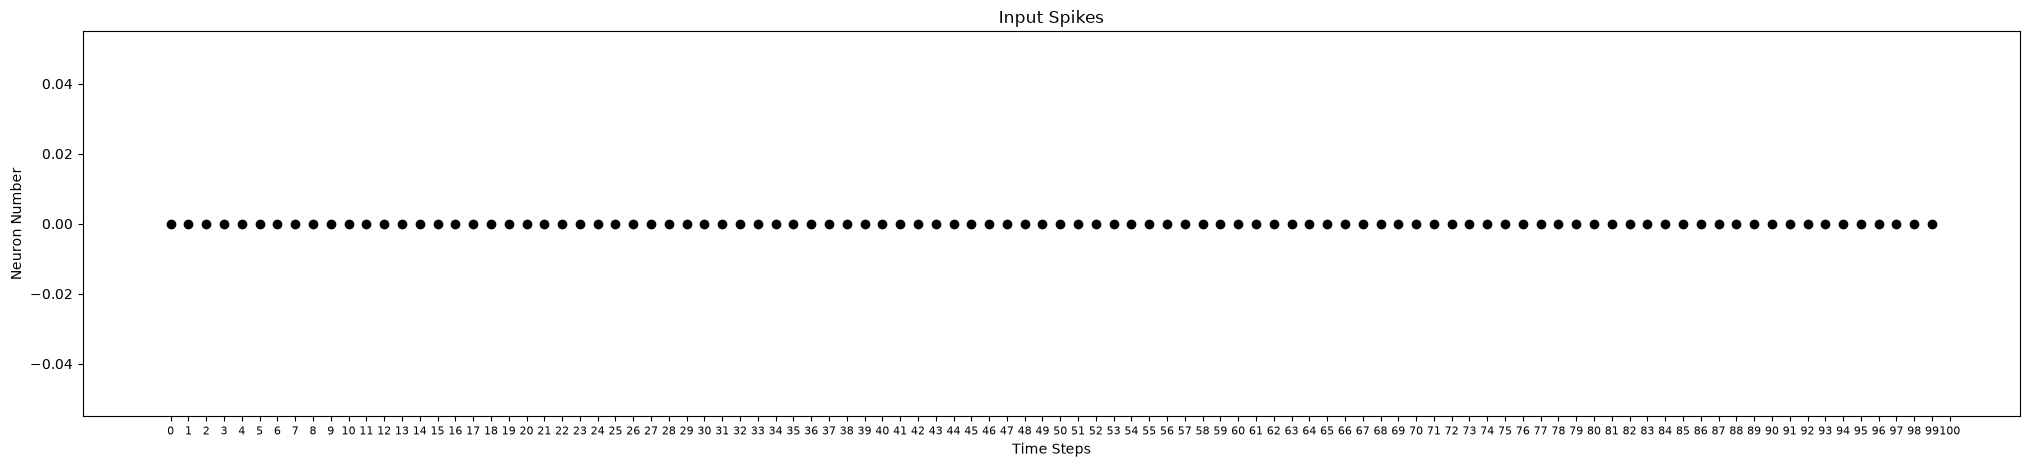

tensor([[0.4570],
        [0.9305],
        [0.7489],
        [0.7623]])
Input weights are all positive
The minimum distance between any two spikes = [ 1.  1. 10.  1.], which should be higher than the set refractory period of 0


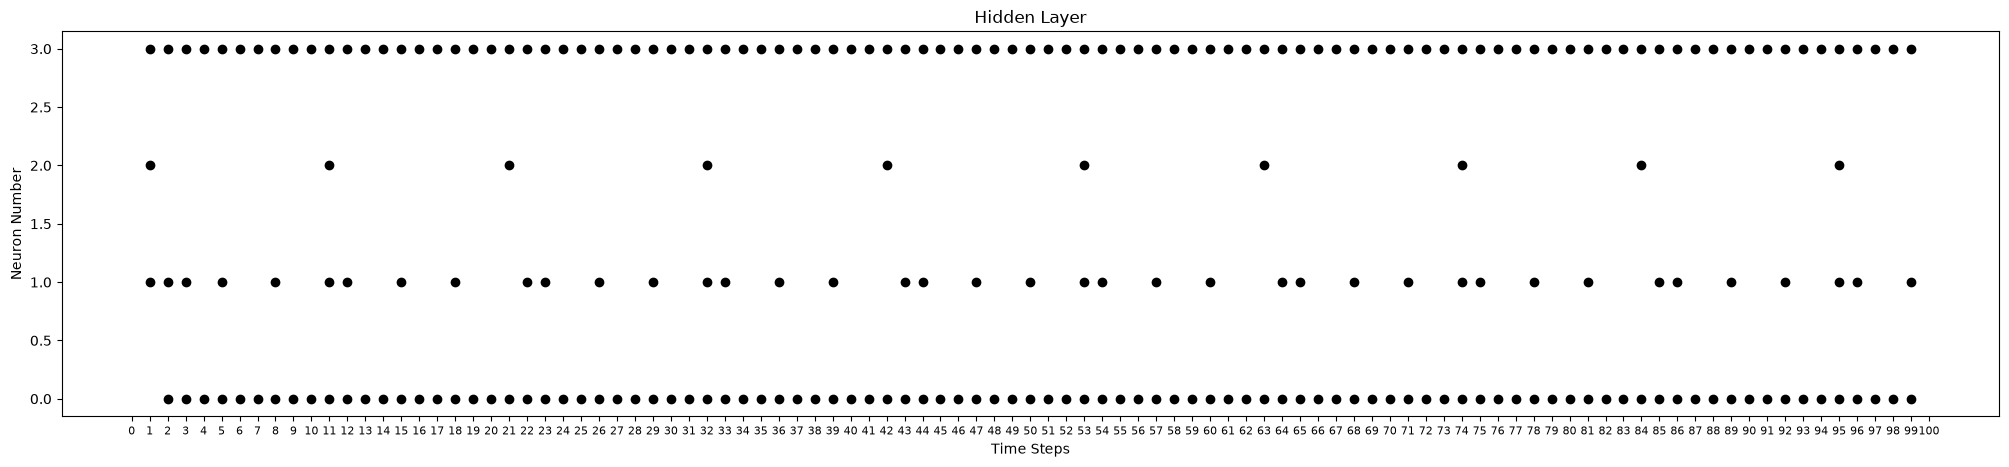

tensor([[0.8482],
        [1.7764],
        [0.8895],
        [1.1066]])
Input weights are all positive
The minimum distance between any two spikes = [2. 2. 2. 2.], which should be higher than the set refractory period of 1


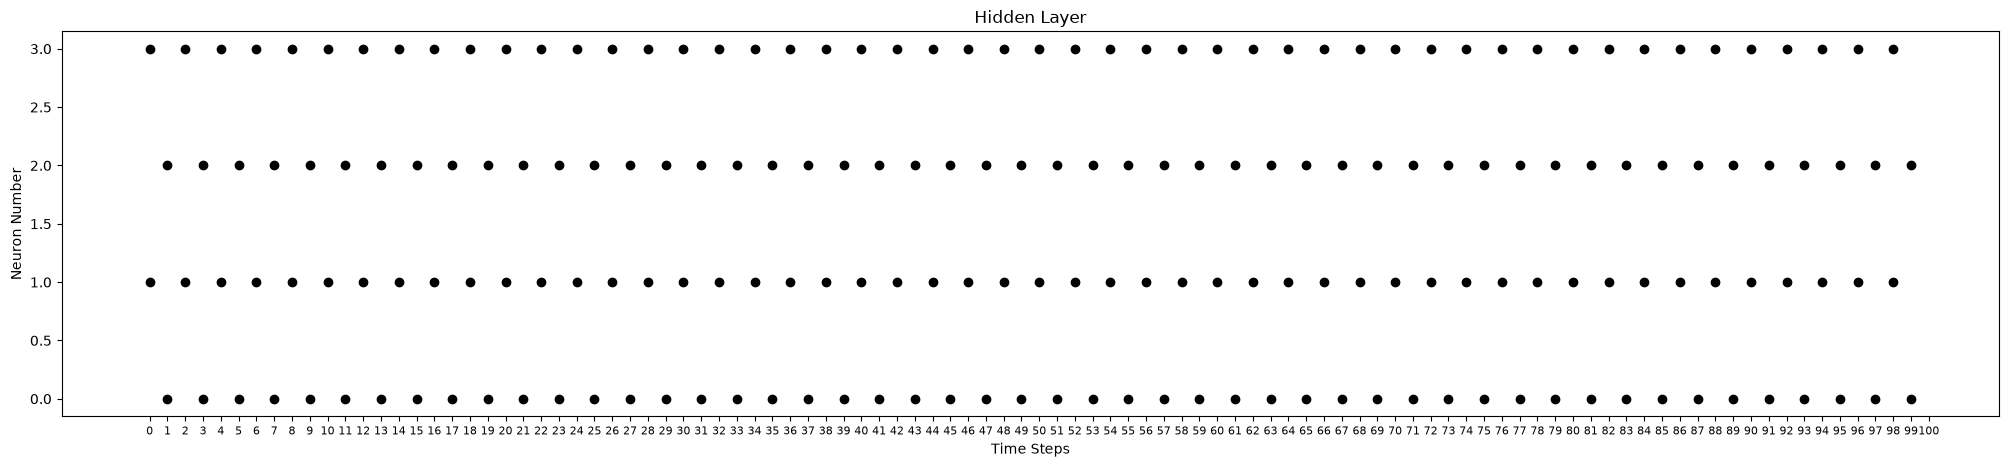

tensor([[0.6020],
        [0.5457],
        [1.5198],
        [0.9302]])
Input weights are all positive
The minimum distance between any two spikes = [3. 3. 3. 3.], which should be higher than the set refractory period of 2


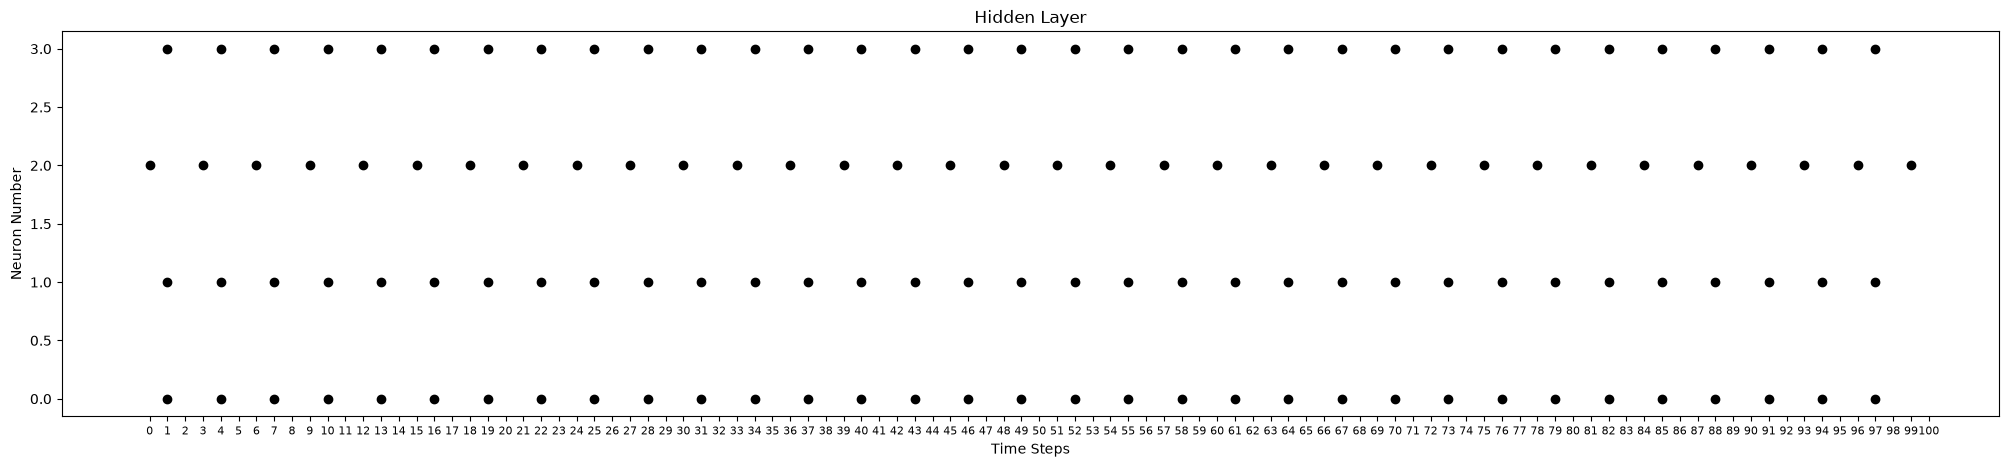

tensor([[1.2820],
        [0.2277],
        [1.4198],
        [0.2017]])
Input weights are all positive
The minimum distance between any two spikes = [ 4. 10.  4. nan], which should be higher than the set refractory period of 3


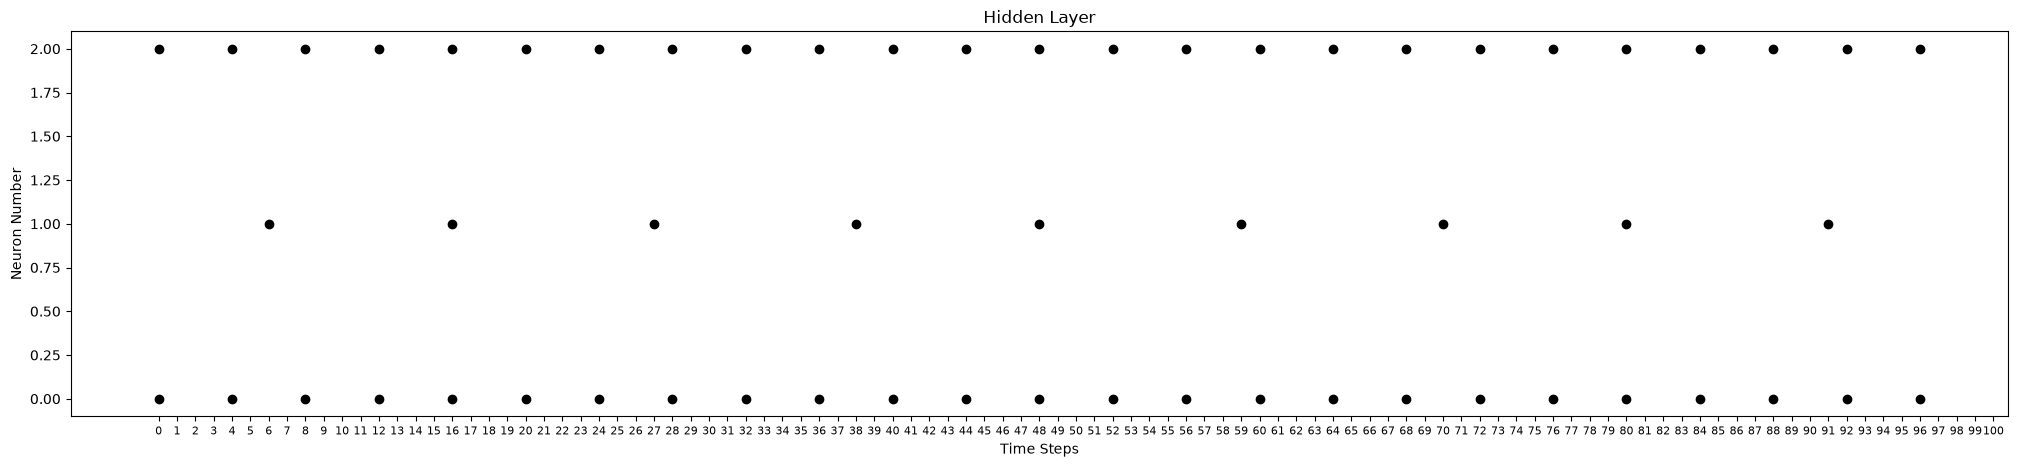

tensor([[0.5687],
        [0.2490],
        [1.4570],
        [0.5766]])
Input weights are all positive
The minimum distance between any two spikes = [5. 5. 5. 5.], which should be higher than the set refractory period of 4


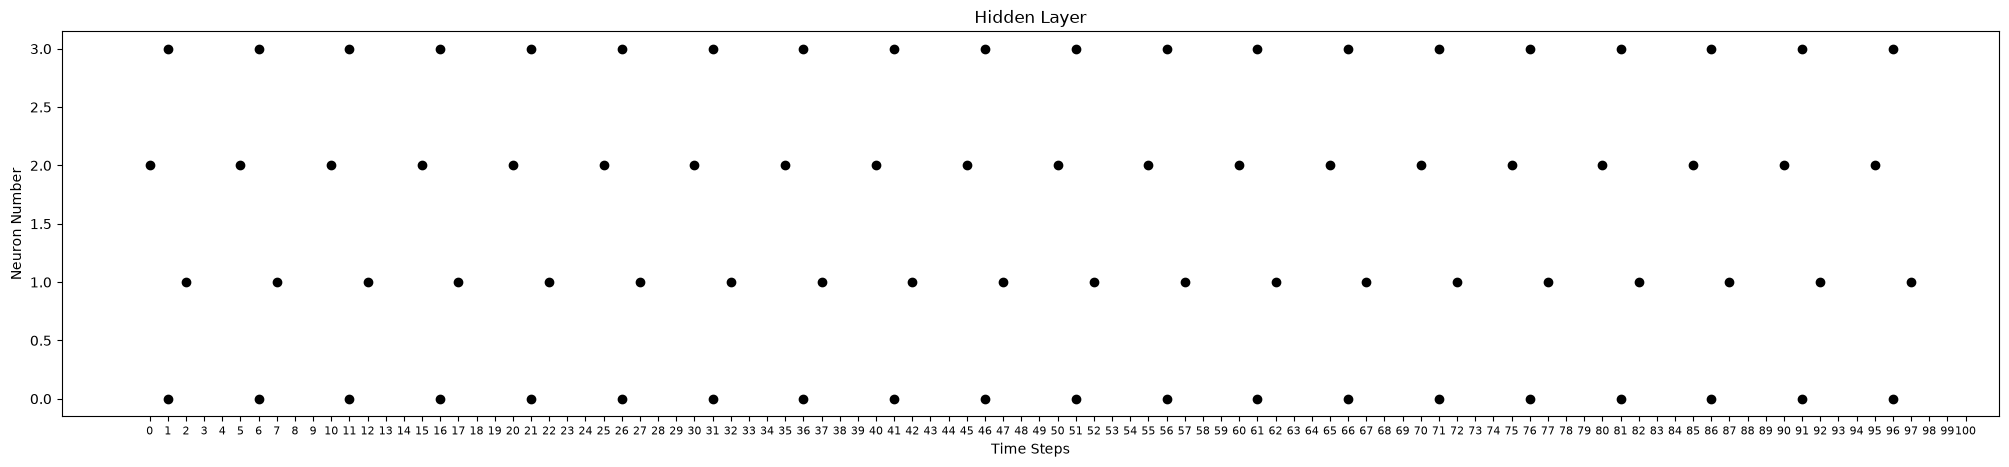

tensor([[1.0441],
        [0.2888],
        [1.3517],
        [1.5842]])
Input weights are all positive
The minimum distance between any two spikes = [ 6. 12.  6.  6.], which should be higher than the set refractory period of 5


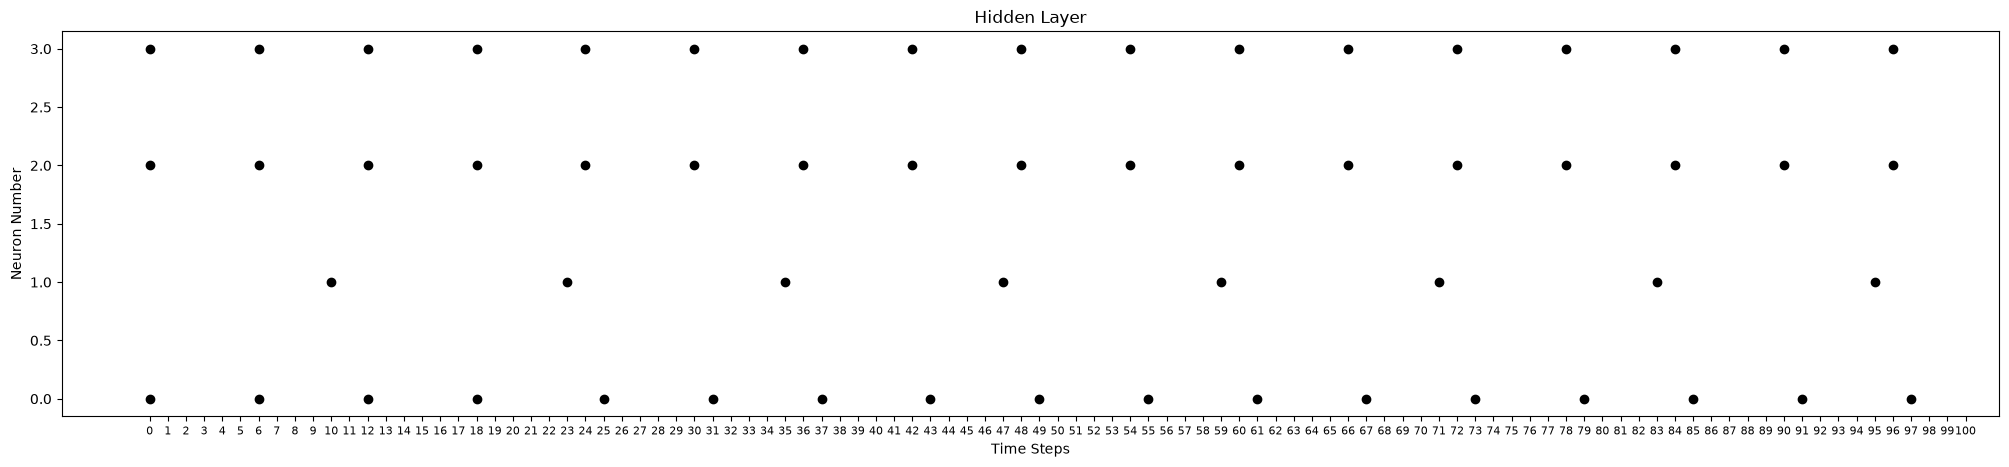

In [107]:
from snntorch.surrogate import fast_sigmoid

from thesis_code import SRNN
from thesis_code.network_components.layers import OutputLayer

refractory_periods = [0, 1, 2, 3, 4, 5]

n_in = 1
n_hidden = 4

num_steps = 100
raw_vector = torch.ones(num_steps, n_in)*1.0
rate_coded_vector = torch.bernoulli(raw_vector)

plot_spikes(rate_coded_vector, "Input Spikes")

for rp in refractory_periods:
    net = SRNN(
        rec_layers=[StandardRecurrentLayer(
            forward_matrix=torch.ones(n_in, n_hidden, device=device),
            recurrent_matrix=torch.ones(n_hidden, n_hidden, device=device),
            beta=0.9,
            spike_grad=fast_sigmoid(slope=25),
            refractory_period=rp,
        )],
        out_layer=OutputLayer(
            n_in=n_hidden,
            n_out=10,
            beta=0.9
        )
    ).to(device)

    data = rate_coded_vector.unsqueeze(1)
    spk_outs, mem_outs, hidden_spks = net.forward_sequence(data)
    hidden_spks = hidden_spks[0].squeeze()

    min_spk_dist = isi_per_neuron(hidden_spks, time_axis=0)
    print(f"The minimum distance between any two spikes = {min_spk_dist}, which should be higher than the set refractory period of {rp}")

    plot_spikes(hidden_spks, "Hidden Layer")